# Saudi Arabia Used Car Price Prediction: Regression Modeling & Hyperparameter Tuning

## The problem
Used cars in Saudi Arabia are mostly sold through classifieds such as **Haraj**, dealer showrooms and newer marketplaces such as Syarah. On these channels the price is whatever the seller types in, many ads say *"negotiable"*, and buyers have no neutral benchmark. Buyers overpay, honest sellers get undercut, and banks, insurers and dealers value cars by hand.

## The goal
Build a model that predicts the **asking price (SAR)** of a used car from its brand, model, options level, age, mileage and engine size, so that marketplaces, dealers, lenders and buyers get a fair-value reference in seconds.

## The workflow
This notebook runs an end-to-end machine learning workflow: load and explore the data, clean it, engineer an `Age` feature, train baseline regressors, tune the best one with **Optuna**, and evaluate it on a held-out test set.

## 0. Setup

In [1]:
!pip install -q optuna

In [2]:
import os
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import xgboost as xgb
import optuna

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer, make_column_selector
from sklearn.impute import SimpleImputer

# Plotting style, and hide noisy warnings
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
# Fixed reference year so results do not change when the calendar year changes.
# (Any constant gives the same model results; it only shifts Age by a fixed amount.)
REFERENCE_YEAR = 2025

## 1. Load Data
We download the Saudi used cars dataset from Kaggle and load the cleaned English version.

In [3]:
# Download latest version of the dataset
path = kagglehub.dataset_download("turkibintalib/saudi-arabia-used-cars-dataset")
print("Path to dataset files:", path)

# Load the clean English dataset
target_file = "UsedCarsSA_Clean_EN.csv"
df = pd.read_csv(os.path.join(path, target_file))

print(f"Successfully loaded English dataset: {target_file}")
display(df.head())
print(df.info())

Path to dataset files: /kaggle/input/saudi-arabia-used-cars-dataset
Successfully loaded English dataset: UsedCarsSA_Clean_EN.csv


,Make,Type,Year,Origin,Color,Options,Engine_Size,Fuel_Type,Gear_Type,Mileage,Region,Price,Negotiable
0,Chrysler,C300,2018,Saudi,Black,Full,5.7,Gas,Automatic,103000,Riyadh,114000,False
1,Nissan,Patrol,2016,Saudi,White,Full,4.8,Gas,Automatic,5448,Riyadh,0,True
2,Nissan,Sunny,2019,Saudi,Silver,Standard,1.5,Gas,Automatic,72418,Riyadh,27500,False
3,Hyundai,Elantra,2019,Saudi,Grey,Standard,1.6,Gas,Automatic,114154,Riyadh,43000,False
4,Hyundai,Elantra,2019,Saudi,Silver,Semi Full,2.0,Gas,Automatic,41912,Riyadh,59500,False


<class 'pandas.DataFrame'>
RangeIndex: 8035 entries, 0 to 8034
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Make         8035 non-null   str    
 1   Type         8035 non-null   str    
 2   Year         8035 non-null   int64  
 3   Origin       8035 non-null   str    
 4   Color        8035 non-null   str    
 5   Options      8035 non-null   str    
 6   Engine_Size  8035 non-null   float64
 7   Fuel_Type    8035 non-null   str    
 8   Gear_Type    8035 non-null   str    
 9   Mileage      8035 non-null   int64  
 10  Region       8035 non-null   str    
 11  Price        8035 non-null   int64  
 12  Negotiable   8035 non-null   bool   
dtypes: bool(1), float64(1), int64(3), str(8)
memory usage: 761.3 KB
None


## 2. Exploratory Data Analysis (EDA)
Listings marked *Negotiable* have no usable price, so for both the analysis and the modeling we only keep **fixed-price listings**. We then look at the price distribution, how listings and prices change with manufacturing year, and how price varies across the top brands.

Fixed-price listings: 5509 of 8035


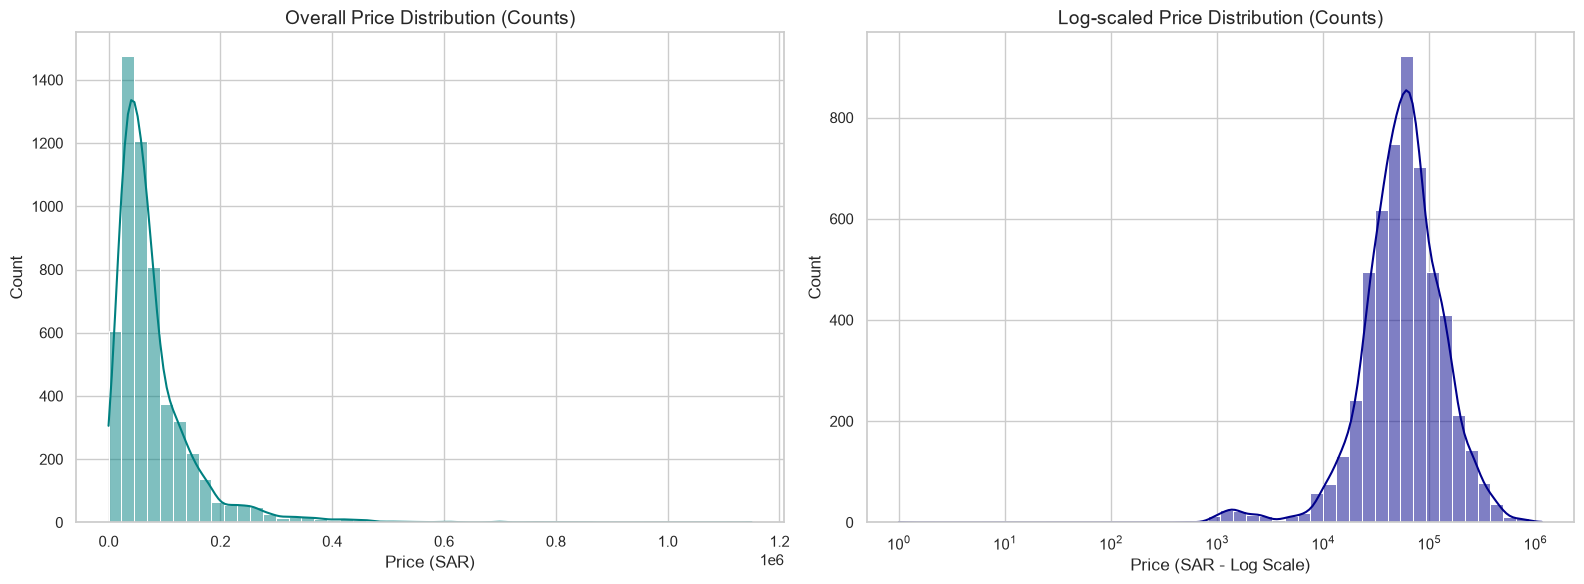

In [4]:
# Fixed-price listings only (the same rows we model later)
df_fixed = df[df["Negotiable"] == False].copy()
df_fixed["Price"] = pd.to_numeric(df_fixed["Price"], errors="coerce")
df_fixed = df_fixed.dropna(subset=["Price"])
print(f"Fixed-price listings: {len(df_fixed)} of {len(df)}")

# 1. Price distribution on linear and logarithmic scales
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.histplot(df_fixed["Price"], bins=50, kde=True, color="teal", ax=axes[0])
axes[0].set_title("Overall Price Distribution (Counts)", fontsize=14)
axes[0].set_xlabel("Price (SAR)", fontsize=12)
axes[0].set_ylabel("Count", fontsize=12)

sns.histplot(df_fixed["Price"][df_fixed["Price"] > 0], bins=50, kde=True,
             color="darkblue", log_scale=True, ax=axes[1])
axes[1].set_title("Log-scaled Price Distribution (Counts)", fontsize=14)
axes[1].set_xlabel("Price (SAR - Log Scale)", fontsize=12)
axes[1].set_ylabel("Count", fontsize=12)

plt.tight_layout()
plt.show()

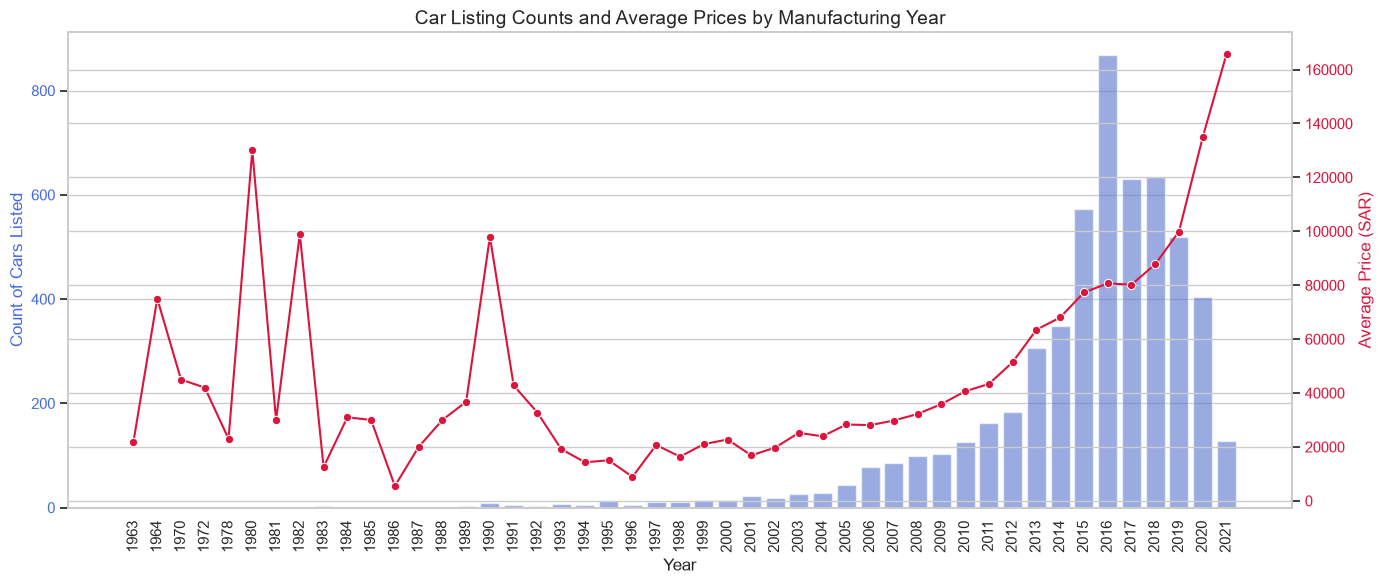

In [5]:
# 2. Listing counts and average price by manufacturing year
year_stats = df_fixed.groupby("Year").agg(
    Count=("Price", "count"),
    Average_Price=("Price", "mean"),
).reset_index()

fig, ax1 = plt.subplots(figsize=(14, 6))

# Bars: listings per year
sns.barplot(data=year_stats, x="Year", y="Count", alpha=0.6, color="royalblue", ax=ax1)
ax1.set_ylabel("Count of Cars Listed", color="royalblue", fontsize=12)
ax1.tick_params(axis="y", labelcolor="royalblue")
ax1.set_title("Car Listing Counts and Average Prices by Manufacturing Year", fontsize=14)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=90)

# Line: average price trend
ax2 = ax1.twinx()
sns.lineplot(data=year_stats, x=ax1.get_xticks(), y="Average_Price",
             color="crimson", marker="o", sort=False, ax=ax2)
ax2.set_ylabel("Average Price (SAR)", color="crimson", fontsize=12)
ax2.tick_params(axis="y", labelcolor="crimson")

plt.tight_layout()
plt.show()

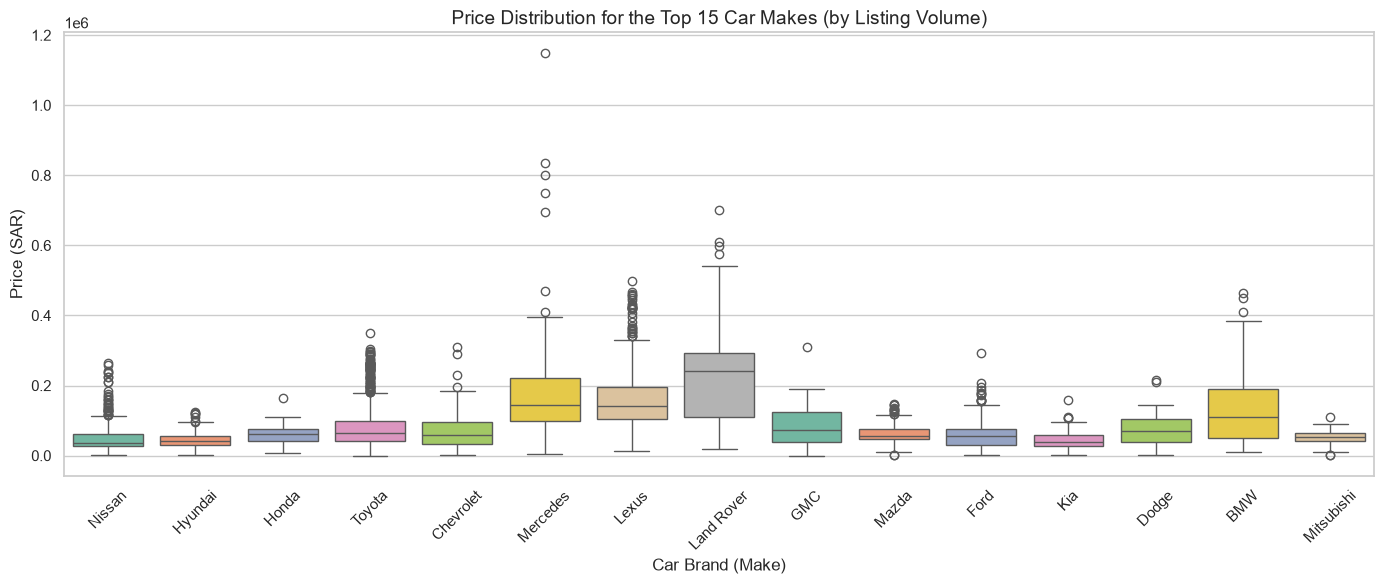

,Make,Type,Year,Origin,Color,Options,Engine_Size,Fuel_Type,Gear_Type,Mileage,Region,Price,Negotiable
count,5509,5509,5509.000000,5509,5509,5509,5509.000000,5509,5509,5.509000e+03,5509,5.509000e+03,5509
unique,57,352,NaN,4,15,3,NaN,3,2,NaN,27,NaN,1
top,Toyota,Camry,NaN,Saudi,White,Full,NaN,Gas,Automatic,NaN,Riyadh,NaN,False
freq,1263,209,NaN,4144,2305,2104,NaN,5408,4936,NaN,2308,NaN,5509
mean,NaN,NaN,2014.839354,NaN,NaN,NaN,3.178199,NaN,NaN,1.393866e+05,NaN,7.832241e+04,NaN
std,NaN,NaN,5.141689,NaN,NaN,NaN,1.465604,NaN,NaN,3.348441e+05,NaN,7.502902e+04,NaN
min,NaN,NaN,1963.000000,NaN,NaN,NaN,1.000000,NaN,NaN,1.000000e+02,NaN,0.000000e+00,NaN
25%,NaN,NaN,2013.000000,NaN,NaN,NaN,2.000000,NaN,NaN,4.600000e+04,NaN,3.500000e+04,NaN
50%,NaN,NaN,2016.000000,NaN,NaN,NaN,2.700000,NaN,NaN,1.010000e+05,NaN,5.800000e+04,NaN
75%,NaN,NaN,2018.000000,NaN,NaN,NaN,4.000000,NaN,NaN,1.800000e+05,NaN,9.500000e+04,NaN


In [6]:
# 3. Price distribution for the 15 brands with the most listings
top_makes = df_fixed["Make"].value_counts().nlargest(15).index
df_top_makes = df_fixed[df_fixed["Make"].isin(top_makes)]

plt.figure(figsize=(14, 6))
sns.boxplot(data=df_top_makes, x="Make", y="Price", hue="Make", palette="Set2", legend=False)
plt.xticks(rotation=45)
plt.title("Price Distribution for the Top 15 Car Makes (by Listing Volume)", fontsize=14)
plt.xlabel("Car Brand (Make)", fontsize=12)
plt.ylabel("Price (SAR)", fontsize=12)
plt.tight_layout()
plt.show()

# Summary statistics for every column
display(df_fixed.describe(include="all"))

## 3. Data Cleaning & Feature Engineering
We remove rows with missing values and logical anomalies (negative prices or mileage, zero-size engines). Then, instead of the absolute manufacturing `Year`, we use **`Age`** (reference year minus `Year`), which lets models represent depreciation more directly.

In [7]:
# 1. Cleaning: drop missing values and logical anomalies
df_cleaned = df_fixed.dropna().copy()
df_cleaned = df_cleaned[
    (df_cleaned["Price"] >= 0)
    & (df_cleaned["Mileage"] >= 0)
    & (df_cleaned["Engine_Size"] > 0)
]

# 2. Feature engineering: Age instead of Year
df_cleaned["Age"] = REFERENCE_YEAR - df_cleaned["Year"]

print(f"Rows after cleaning: {len(df_cleaned)}")
display(df_cleaned[["Year", "Age", "Mileage", "Engine_Size", "Price"]].head())

Rows after cleaning: 5509


,Year,Age,Mileage,Engine_Size,Price
0,2018,7,103000,5.7,114000
2,2019,6,72418,1.5,27500
3,2019,6,114154,1.6,43000
4,2019,6,41912,2.0,59500
5,2018,7,39000,1.5,72000


### Correlation of numeric features

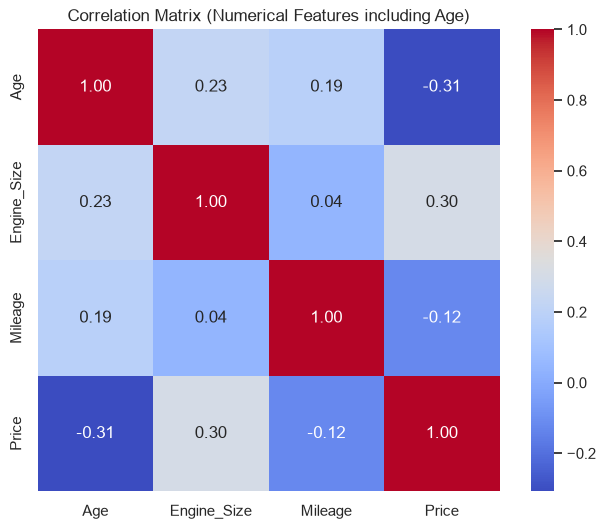

In [8]:
numeric_cols = ["Age", "Engine_Size", "Mileage", "Price"]
plt.figure(figsize=(8, 6))
sns.heatmap(df_cleaned[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation Matrix (Numerical Features including Age)")
plt.show()

## 4. Train / Validation / Test Split & Preprocessing
To prevent data leakage during hyperparameter tuning we use a three-way split: **60% train, 20% validation, 20% test**. The test set is only used once, at the very end.

Preprocessing is a scikit-learn column transformer: median imputation plus standard scaling for numeric columns, and most-frequent imputation plus one-hot encoding for categorical columns. Scaling does not affect the tree-based models, but it keeps Linear Regression numerically stable (mileage is in the tens of thousands, while the one-hot columns are 0 or 1).

In [9]:
# Features and target
target_col = "Price"
X = df_cleaned.drop(columns=[target_col, "Negotiable", "Year"], errors="ignore")
y = df_cleaned[target_col]

# First split: 80% train+validation, 20% test
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
# Second split: 75% / 25% of the 80%  ->  60% train, 20% validation overall
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=RANDOM_STATE
)

print("=== Three-Way Split ===")
print(f"Train size (60%):      {X_train.shape[0]}")
print(f"Validation size (20%): {X_val.shape[0]}")
print(f"Test size (20%):       {X_test.shape[0]}")

# Preprocessing pipeline
preprocessor = make_column_transformer(
    (make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler()),
     make_column_selector(dtype_include="number")),
    (make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
     make_column_selector(dtype_include="object")),
)
print("Preprocessing pipeline created successfully.")

=== Three-Way Split ===
Train size (60%):      3305
Validation size (20%): 1102
Test size (20%):       1102
Preprocessing pipeline created successfully.


## 5. Baseline Models: Model Complexity Analysis
Before tuning anything, we establish baselines with three models of increasing complexity:

1. **Linear Regression**: low complexity
2. **Random Forest**: medium-high complexity (bagging)
3. **XGBoost**: high complexity (boosting)

Each model is trained on the 60% training split and evaluated on both the training and test sets. A big gap between the two means the model is overfitting.

[Linear Regression] Train R2: 0.7487 | Test R2: 0.6492


[Random Forest] Train R2: 0.9751 | Test R2: 0.7587


[XGBoost] Train R2: 0.9757 | Test R2: 0.7852


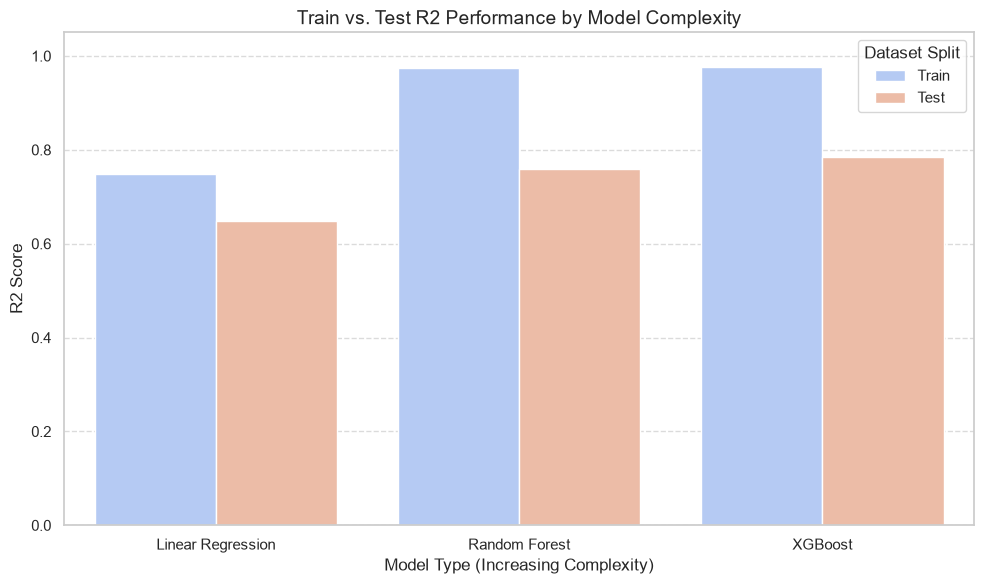

In [10]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": xgb.XGBRegressor(n_estimators=100, random_state=RANDOM_STATE),
}

fitted_pipelines = {}
test_preds = {}
train_r2_scores, test_r2_scores = [], []

for name, model in models.items():
    # Wrap each model with the preprocessing pipeline and fit on the training split
    pipeline = make_pipeline(preprocessor, model)
    pipeline.fit(X_train, y_train)

    fitted_pipelines[name] = pipeline
    test_preds[name] = pipeline.predict(X_test)

    train_r2 = pipeline.score(X_train, y_train)
    test_r2 = pipeline.score(X_test, y_test)
    train_r2_scores.append(train_r2)
    test_r2_scores.append(test_r2)
    print(f"[{name}] Train R2: {train_r2:.4f} | Test R2: {test_r2:.4f}")

# Tidy DataFrame for plotting
model_names = list(models.keys())
plot_df = pd.DataFrame({
    "Model": model_names * 2,
    "R2 Score": train_r2_scores + test_r2_scores,
    "Dataset Split": ["Train"] * len(model_names) + ["Test"] * len(model_names),
})

plt.figure(figsize=(10, 6))
sns.barplot(data=plot_df, x="Model", y="R2 Score", hue="Dataset Split", palette="coolwarm")
plt.title("Train vs. Test R2 Performance by Model Complexity", fontsize=14)
plt.xlabel("Model Type (Increasing Complexity)", fontsize=12)
plt.ylabel("R2 Score", fontsize=12)
plt.ylim(0, 1.05)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

## 6. Hyperparameter Tuning with Optuna
XGBoost is the most promising baseline, so we tune it with Optuna. The search is scored **only on the validation split**, and it includes strong regularization (`reg_alpha`, `reg_lambda`) to limit overfitting.

In [11]:
optuna.logging.set_verbosity(optuna.logging.WARNING)


def objective_regularized_xgb(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 300),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 8),
        "subsample": trial.suggest_float("subsample", 0.5, 0.9),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 0.9),
        # Regularization
        "reg_alpha": trial.suggest_float("reg_alpha", 0.1, 100.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 100.0, log=True),
        "random_state": RANDOM_STATE,
        "n_jobs": -1,
    }

    pipeline = make_pipeline(preprocessor, xgb.XGBRegressor(**params))
    pipeline.fit(X_train, y_train)                 # train on the 60% split
    preds = pipeline.predict(X_val)                # score on the 20% validation split
    return r2_score(y_val, preds)


study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)
study.optimize(objective_regularized_xgb, n_trials=100)

print("=== Optuna Search Complete ===")
print("Best Validation R2:", study.best_value)
print("Best Params Found:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

=== Optuna Search Complete ===
Best Validation R2: 0.8317044973373413
Best Params Found:
  n_estimators: 291
  learning_rate: 0.08154885989237474
  max_depth: 8
  subsample: 0.5371954903249833
  colsample_bytree: 0.8719162150405748
  reg_alpha: 15.264911127706124
  reg_lambda: 0.30263833248999095


In [12]:
# Re-train the champion XGBoost model with the best parameters on the training split
final_xgb_model = xgb.XGBRegressor(**study.best_params, random_state=RANDOM_STATE, n_jobs=-1)
final_pipeline = make_pipeline(preprocessor, final_xgb_model)
final_pipeline.fit(X_train, y_train)

final_test_preds = final_pipeline.predict(X_test)
print("=== Final Optimized & Regularized XGBoost ===")
print(f"Test R2:       {r2_score(y_test, final_test_preds):.4f}")
print(f"Test MAE (SAR): {mean_absolute_error(y_test, final_test_preds):.2f}")

=== Final Optimized & Regularized XGBoost ===
Test R2:       0.8202
Test MAE (SAR): 15433.69


## 7. Comparison: Baseline XGBoost vs. Optuna-Optimized XGBoost
We compare the baseline and tuned XGBoost on the training and test splits to see the effect of regularization and tuning on generalization.

,Model Version,Dataset Split,R2 Score,MAE (SAR)
0,Baseline XGBoost,Train,0.975682,7537.924316
1,Baseline XGBoost,Test,0.785203,17072.144531
2,Optuna Optimized,Train,0.984933,6597.359375
3,Optuna Optimized,Test,0.820215,15433.687500


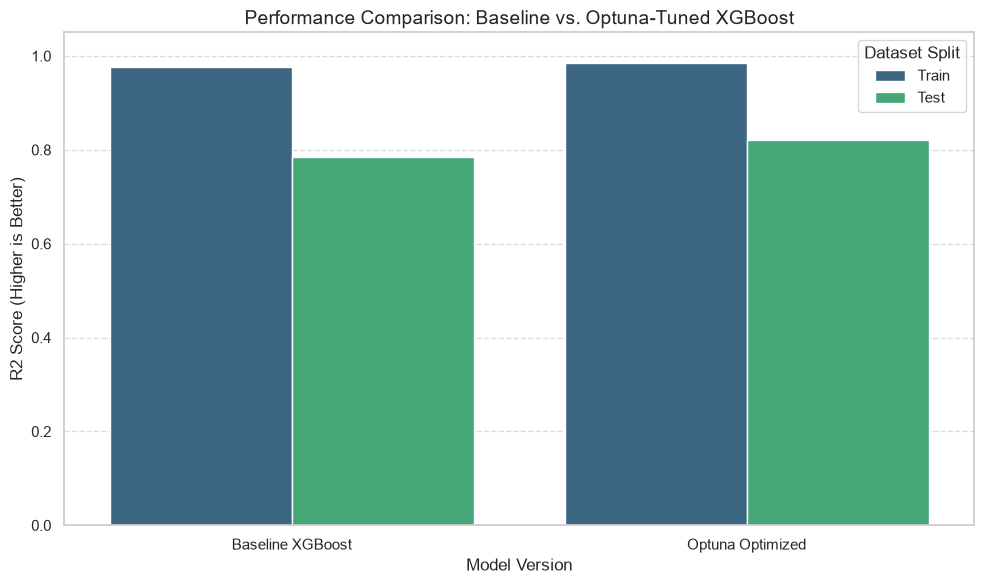

In [13]:
baseline_pipeline = fitted_pipelines["XGBoost"]

comparison_df = pd.DataFrame({
    "Model Version": ["Baseline XGBoost", "Baseline XGBoost", "Optuna Optimized", "Optuna Optimized"],
    "Dataset Split": ["Train", "Test", "Train", "Test"],
    "R2 Score": [
        baseline_pipeline.score(X_train, y_train),
        baseline_pipeline.score(X_test, y_test),
        final_pipeline.score(X_train, y_train),
        final_pipeline.score(X_test, y_test),
    ],
    "MAE (SAR)": [
        mean_absolute_error(y_train, baseline_pipeline.predict(X_train)),
        mean_absolute_error(y_test, test_preds["XGBoost"]),
        mean_absolute_error(y_train, final_pipeline.predict(X_train)),
        mean_absolute_error(y_test, final_test_preds),
    ],
})
display(comparison_df)

plt.figure(figsize=(10, 6))
sns.barplot(data=comparison_df, x="Model Version", y="R2 Score", hue="Dataset Split", palette="viridis")
plt.title("Performance Comparison: Baseline vs. Optuna-Tuned XGBoost", fontsize=14)
plt.ylabel("R2 Score (Higher is Better)", fontsize=12)
plt.xlabel("Model Version", fontsize=12)
plt.ylim(0, 1.05)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

## 8. Final Evaluation on the Held-Out Test Set
The test set was not used for training or tuning, so these numbers are our unbiased estimate of real-world performance.

--- Final Unbiased Performance on the Held-Out Test Set ---


,Metric,Optuna Optimized & Regularized XGBoost (Test Set)
0,MAE (SAR),15433.687500
1,RMSE (SAR),35053.597362
2,R2 Score,0.820215


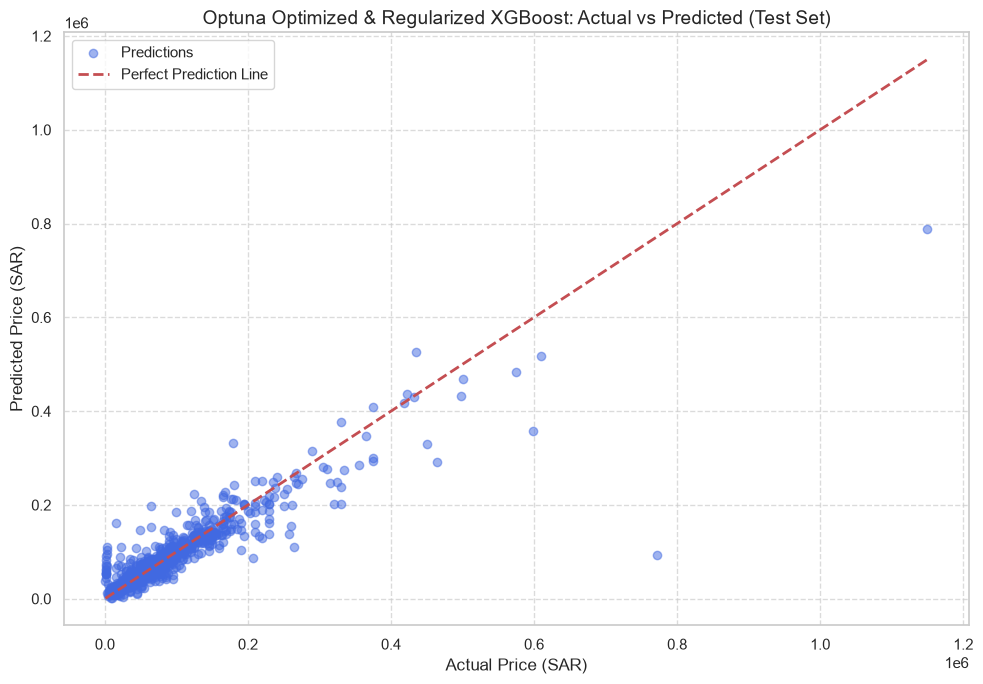

In [14]:
final_test_mae = mean_absolute_error(y_test, final_test_preds)
final_test_rmse = np.sqrt(mean_squared_error(y_test, final_test_preds))
final_test_r2 = r2_score(y_test, final_test_preds)

final_test_comparison = pd.DataFrame({
    "Metric": ["MAE (SAR)", "RMSE (SAR)", "R2 Score"],
    "Optuna Optimized & Regularized XGBoost (Test Set)": [final_test_mae, final_test_rmse, final_test_r2],
})
print("--- Final Unbiased Performance on the Held-Out Test Set ---")
display(final_test_comparison)

# Actual vs. predicted
plt.figure(figsize=(10, 7))
plt.scatter(y_test, final_test_preds, alpha=0.5, color="royalblue", label="Predictions")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2, label="Perfect Prediction Line")
plt.xlabel("Actual Price (SAR)", fontsize=12)
plt.ylabel("Predicted Price (SAR)", fontsize=12)
plt.title("Optuna Optimized & Regularized XGBoost: Actual vs Predicted (Test Set)", fontsize=14)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

### Model progression: all four models side by side

,Model,Test R2 Score,Test MAE (SAR)
0,Linear Regression,0.649205,23743.053061
1,Random Forest (Baseline),0.758674,16619.181833
2,XGBoost (Baseline),0.785203,17072.144531
3,XGBoost (Optuna Tuned),0.820215,15433.687500


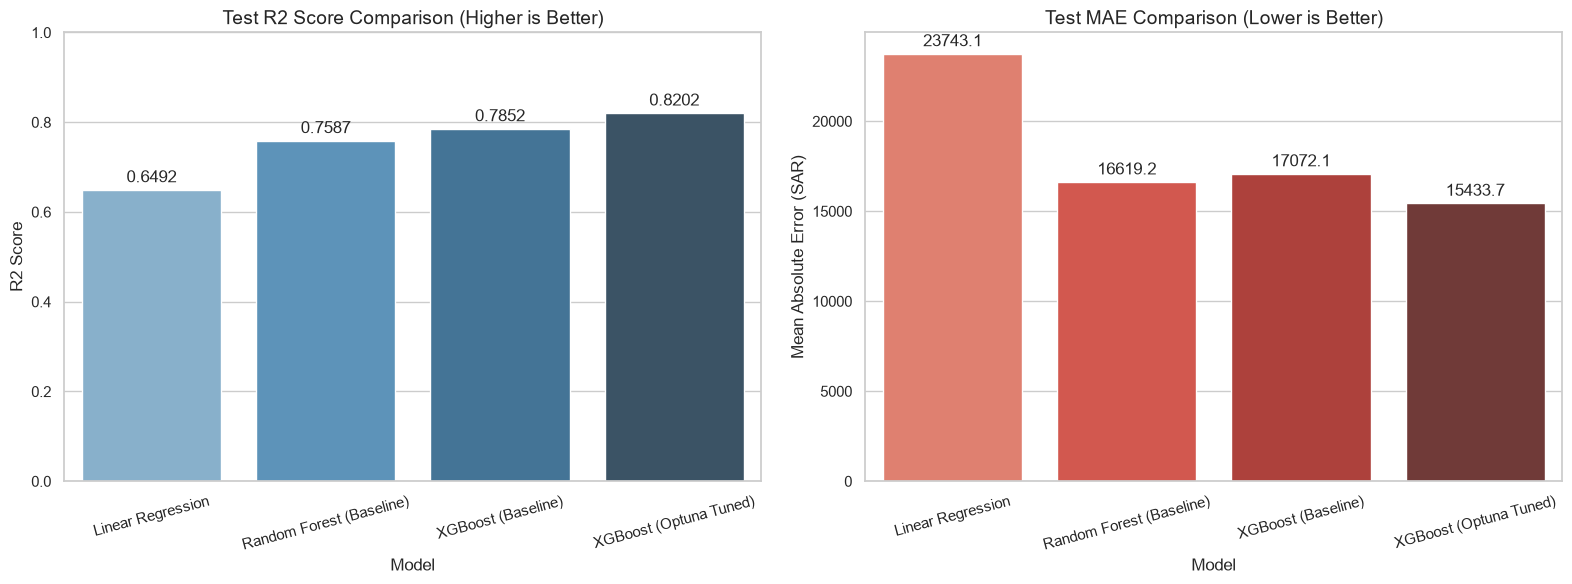

In [15]:
results_df = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest (Baseline)", "XGBoost (Baseline)", "XGBoost (Optuna Tuned)"],
    "Test R2 Score": [
        r2_score(y_test, test_preds["Linear Regression"]),
        r2_score(y_test, test_preds["Random Forest"]),
        r2_score(y_test, test_preds["XGBoost"]),
        r2_score(y_test, final_test_preds),
    ],
    "Test MAE (SAR)": [
        mean_absolute_error(y_test, test_preds["Linear Regression"]),
        mean_absolute_error(y_test, test_preds["Random Forest"]),
        mean_absolute_error(y_test, test_preds["XGBoost"]),
        mean_absolute_error(y_test, final_test_preds),
    ],
})
display(results_df)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=results_df, x="Model", y="Test R2 Score", hue="Model", palette="Blues_d", ax=axes[0], legend=False)
axes[0].set_title("Test R2 Score Comparison (Higher is Better)", fontsize=14)
axes[0].set_ylabel("R2 Score", fontsize=12)
axes[0].set_xlabel("Model", fontsize=12)
axes[0].set_ylim(0, 1.0)
axes[0].tick_params(axis="x", rotation=15)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.4f", padding=3)

sns.barplot(data=results_df, x="Model", y="Test MAE (SAR)", hue="Model", palette="Reds_d", ax=axes[1], legend=False)
axes[1].set_title("Test MAE Comparison (Lower is Better)", fontsize=14)
axes[1].set_ylabel("Mean Absolute Error (SAR)", fontsize=12)
axes[1].set_xlabel("Model", fontsize=12)
axes[1].tick_params(axis="x", rotation=15)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f", padding=3)

plt.tight_layout()
plt.show()

## 9. Feature Importances & Key Drivers of Price
Finally, we look at which features the champion model relies on most, to see what drives used car prices in the Saudi market.

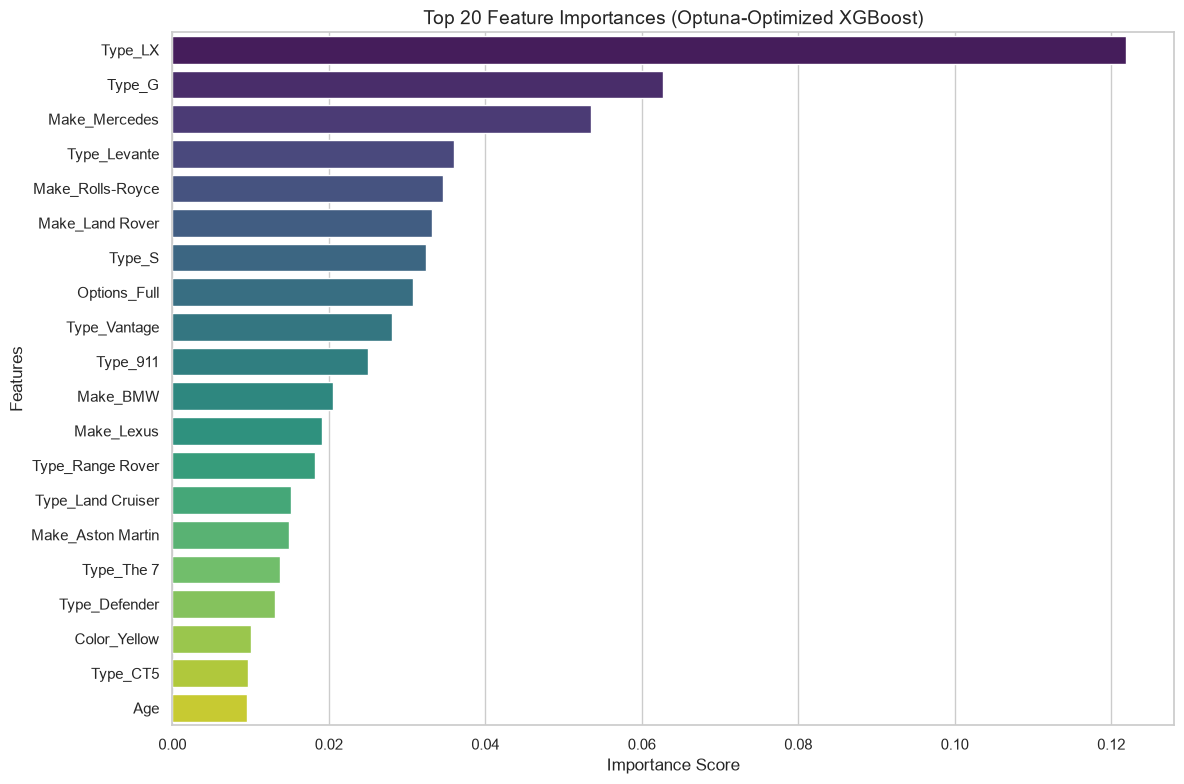

In [16]:
# Final estimator and fitted preprocessor from the champion pipeline
champion_xgb_estimator = final_pipeline[-1]
fitted_preprocessor = final_pipeline[0]
importances = champion_xgb_estimator.feature_importances_

# Recover the encoded feature names from the preprocessor
encoded_features = []
for name, trans, cols in fitted_preprocessor.transformers_:
    if name == "remainder":
        continue
    if "onehotencoder" in trans.named_steps:
        encoded_features.extend(trans.named_steps["onehotencoder"].get_feature_names_out(cols))
    else:
        encoded_features.extend(cols)
encoded_features = np.array(encoded_features)

indices = np.argsort(importances)[::-1][:20]

plt.figure(figsize=(12, 8))
sns.barplot(
    x=importances[indices],
    y=encoded_features[indices],
    hue=encoded_features[indices],
    palette="viridis",
    legend=False,
)
plt.title("Top 20 Feature Importances (Optuna-Optimized XGBoost)", fontsize=14)
plt.xlabel("Importance Score", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.tight_layout()
plt.show()

## 10. Conclusion & Business Value for Saudi Arabia

**What we found**
- Linear Regression is too simple for this market; Random Forest and XGBoost fit the training data almost perfectly but overfit.
- Regularization plus Optuna tuning gives the best generalization, with a test R2 of about 0.82 and an average error of roughly 15,000 SAR.
- Price is driven mostly by **brand and model** (luxury and exotic names such as Land Cruiser LX, Mercedes G-Class, Maserati Levante, Rolls-Royce, Land Rover and Porsche 911) and by the **options level** ("Full").

**Why it matters**
- **Marketplaces such as Haraj and Syarah** can flag listings priced above or below market, suggest a price to sellers, and build trust with buyers.
- **Dealers and fleet owners** can price stock and trade-ins consistently.
- **Banks and insurers** get a quick, consistent vehicle valuation for loans and claims.
- **Buyers and sellers** get a neutral benchmark before they negotiate.

**Limitations**
- The data contains *asking* prices, not final sale prices, and it excludes *Negotiable* listings.
- It is a snapshot with no listing date, and it has no condition or accident history.
- An error of about 15k SAR is large for cheaper cars. Predicting `log(Price)` and adding cross-validation are the natural next steps.